# 8. Sensitivity: lane as a random intercept

Hits are called with lane as a fixed stratum. The obvious alternative is a
mixed model with a lane random intercept. This notebook fits one for every
element and asks whether anything in the hit list depends on that choice.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

import methods as M
from methods import TABLES, load_cells, bh_fdr, style
from methods import BLUE, NEUTRAL, GRID, INK2

## Fit the GLMM per element

**Purpose.** A binomial mixed model, `y ~ perturbed` with a lane random
intercept, fitted by variational Bayes for each element against the pooled
controls.

In [2]:
MIN_CELLS = 55

a = load_cells(assigned_only=True)
state = pd.read_csv(TABLES / "01_cell_state.tsv.gz", sep="\t").set_index("cell_barcode")
obs = a.obs.copy()
obs["state"] = state.reindex(obs.index)["state"].to_numpy()
obs = obs[obs.state.isin(["infected", "uninfected"])].copy()
obs["y"] = (obs.state == "infected").astype(int)
obs["lane"] = obs.gem_group.astype(str)
ntc = obs[obs.is_ntc]

mh = pd.read_csv(TABLES / "03_hits_infection.tsv", sep="\t").set_index("element")
elements = [e for e in mh.index if (obs.element == e).sum() >= MIN_CELLS]
print(f"fitting a lane random-intercept GLMM for {len(elements)} elements "
      f"({len(ntc)} non-targeting cells enter every fit)")

rows, t0 = [], time.time()
for k, el in enumerate(elements, 1):
    sub = pd.concat([obs[obs.element == el].assign(pert=1), ntc.assign(pert=0)])
    if sub.pert.sum() == 0 or sub.y.nunique() < 2:
        continue
    try:
        fit = BinomialBayesMixedGLM.from_formula(
            "y ~ pert", {"lane": "0 + C(lane)"}, sub
        ).fit_vb(verbose=False)
    except Exception as exc:                       # pragma: no cover
        print(f"  {el}: fit failed ({exc})")
        continue
    j = list(fit.model.exog_names).index("pert")
    coef, sd = float(fit.fe_mean[j]), float(fit.fe_sd[j])
    # the fitted lane random-effect scale, on the log-odds scale
    lane_sd = float(np.exp(fit.vcp_mean[0])) if len(fit.vcp_mean) else np.nan
    rows.append(
        dict(
            element=el,
            target=mh.loc[el, "target"],
            is_ntc=bool(mh.loc[el, "is_ntc"]),
            n_cells=int(sub.pert.sum()),
            log_or_glmm=coef,
            se_glmm=sd,
            lane_sd_glmm=lane_sd,
            p_glmm=float(2 * stats.norm.sf(abs(coef / sd))) if sd > 0 else np.nan,
            log_or_mh=float(mh.loc[el, "log_or_mh"]),
            se_mh=float(mh.loc[el, "se_mh"]),
            p_null=float(mh.loc[el, "p_null"]),
            q_null=float(mh.loc[el, "q_null"]),
        )
    )
    if k % 40 == 0:
        print(f"  {k}/{len(elements)} ({time.time() - t0:.0f}s)")

g = pd.DataFrame(rows)
tg = g[~g.is_ntc].copy()
tg["q_glmm"] = bh_fdr(tg.p_glmm.to_numpy())
g = g.merge(tg[["element", "q_glmm"]], on="element", how="left")
g.to_csv(TABLES / "08_glmm_vs_mh.tsv", sep="\t", index=False)

fitting a lane random-intercept GLMM for 184 elements (2250 non-targeting cells enter every fit)


  40/184 (5s)


  80/184 (9s)


  120/184 (15s)


  160/184 (20s)


## Does the hit list change?

**Purpose.** Compare effect sizes, standard errors and the two hit lists.

**What it means.** The estimates are effectively identical (r = 0.9999) and the
hit lists overlap at Jaccard 0.87, with a fitted lane spread of about 0.33 on
the log-odds scale. The two agree because the eight lanes are large and every
element is spread across all of them, so there is little for a random intercept
to shrink. The stratified estimator stays primary: it assumes less, and it is
what the resampling null is built around.

In [3]:
# --------------------------------------------------------------- agreement
t = g[~g.is_ntc]
pear = float(np.corrcoef(t.log_or_glmm, t.log_or_mh)[0, 1])
spear = float(t.log_or_glmm.corr(t.log_or_mh, method="spearman"))
diff = (t.log_or_glmm - t.log_or_mh).abs()
mh_hits = set(t.loc[t.q_null < 0.1, "element"])
glmm_hits = set(t.loc[t.q_glmm < 0.1, "element"])
both = mh_hits & glmm_hits
jac = len(both) / len(mh_hits | glmm_hits) if (mh_hits | glmm_hits) else np.nan
ntc_rows = g[g.is_ntc]

summ = pd.DataFrame(
    [
        ("elements_fitted", len(g)),
        ("targeting_elements", len(t)),
        ("pearson_r_glmm_vs_mh", pear),
        ("spearman_rho_glmm_vs_mh", spear),
        ("median_abs_difference_log_or", float(diff.median())),
        ("max_abs_difference_log_or", float(diff.max())),
        ("median_se_ratio_glmm_over_mh", float((t.se_glmm / t.se_mh).median())),
        ("hits_mh_q<0.1", len(mh_hits)),
        ("hits_glmm_q<0.1", len(glmm_hits)),
        ("hits_in_both", len(both)),
        ("jaccard", jac),
        ("median_lane_sd_logodds", float(g.lane_sd_glmm.median())),
        ("ntc_elements", len(ntc_rows)),
        ("ntc_p_glmm_below_0.05", int((ntc_rows.p_glmm < 0.05).sum())),
    ],
    columns=["metric", "value"],
)
summ.to_csv(TABLES / "08_glmm_summary.tsv", sep="\t", index=False)
print("\nGLMM (lane random intercept) against MH (lane as stratum):")
print(summ.to_string(index=False))

disagree = t.assign(d=diff).nlargest(8, "d")
print("\nwhere the two estimators differ most:")
print(
    disagree[["target", "n_cells", "log_or_mh", "log_or_glmm", "q_null", "q_glmm"]]
    .round(3).to_string(index=False)
)
print(
    "\nThe two agree closely because the eight lanes are large and the "
    "element's cells are spread across all of them, so there is little for a "
    "random intercept to shrink. The fixed-effect stratified estimator is kept "
    "as the primary one: it assumes less, and it is the estimator the "
    "resampling null is built around."
)


GLMM (lane random intercept) against MH (lane as stratum):
                      metric      value
             elements_fitted 184.000000
          targeting_elements 164.000000
        pearson_r_glmm_vs_mh   0.999852
     spearman_rho_glmm_vs_mh   0.999744
median_abs_difference_log_or   0.006292
   max_abs_difference_log_or   0.036576
median_se_ratio_glmm_over_mh   0.966509
               hits_mh_q<0.1  30.000000
             hits_glmm_q<0.1  28.000000
                hits_in_both  27.000000
                     jaccard   0.870968
      median_lane_sd_logodds   0.327703
                ntc_elements  20.000000
       ntc_p_glmm_below_0.05   0.000000

where the two estimators differ most:
      target  n_cells  log_or_mh  log_or_glmm  q_null  q_glmm
       ATG14      113     -1.134       -1.171   0.006   0.000
        BZW2       56     -0.517       -0.544   0.247   0.270
        MIB1       67     -0.176       -0.203   0.740   0.697
       G3BP1       79      0.390        0.363   0.300

## The two estimators, side by side

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


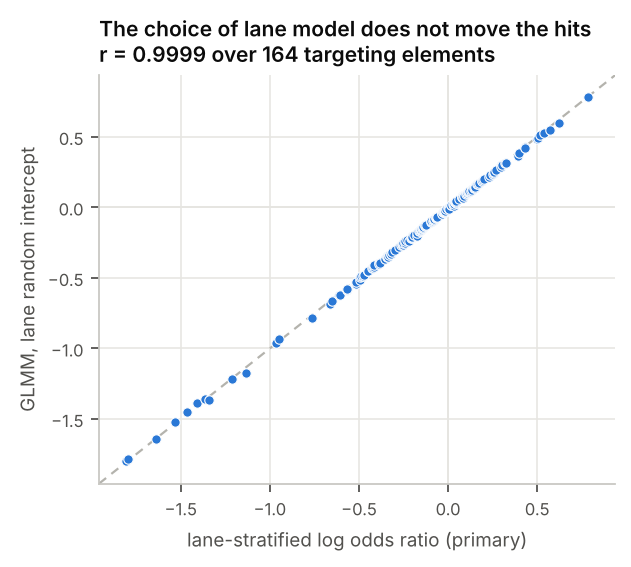

In [4]:
fig, ax = plt.subplots(figsize=(4.0, 3.6))
lim = (t.log_or_mh.min() - 0.15, t.log_or_mh.max() + 0.15)
ax.plot(lim, lim, color=NEUTRAL, linewidth=1.0, linestyle=(0, (4, 3)), zorder=1)
ax.axhline(0, color=GRID, linewidth=0.8)
ax.axvline(0, color=GRID, linewidth=0.8)
ax.scatter(t.log_or_mh, t.log_or_glmm, s=18, color=BLUE, edgecolor="white",
           linewidth=0.5, zorder=3)
style(ax, grid_axis="both")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("lane-stratified log odds ratio (primary)")
ax.set_ylabel("GLMM, lane random intercept")
ax.set_title(f"The choice of lane model does not move the hits\n"
             f"r = {pear:.4f} over {len(t)} targeting elements",
             loc="left", fontsize=9.5)
fig.tight_layout()
plt.show()